In [1]:
import gymnasium as gym

import numpy as np
import time
import matplotlib.pyplot as plt
import random 
import numpy as np
from collections import defaultdict
import copy 
 

env=gym.make('CartPole-v1')#,render_mode='human')

(state,_)=env.reset()

In [2]:
def treatState(state,pos_space,vel_space,ang_space,ang_vel_space):
    state[0]=np.digitize(state[0],pos_space)
    state[1]=np.digitize(state[1],vel_space)
    state[2]=np.digitize(state[2],ang_space)
    state[3]=np.digitize(state[3],ang_vel_space)
    return state

In [3]:
class IncrQlearning():

    def __init__(self, epsilon, gamma, alpha, num_actions,goal):

   
        self.epsilon = epsilon
        self.gamma = gamma
        self.alpha = alpha
        self.Qvalues = defaultdict(lambda : np.repeat(0.0,num_actions))
        self.num_actions=num_actions
        self.goal=goal
        

    def getQvalue(self, state, action):
        return self.Qvalues[state][action]

    
    """
    Compute the action to take in the current state.  With
    probability self.epsilon, we should take a random action and
    take the best policy action otherwise.  Note that if there are
    no legal actions, which is the case at the terminal state, you
    should choose None as the action.
    """
    def getAction(self, state):
        if random.random() < self.epsilon:
          return random.randint(0,self.num_actions-1)
        else:
          return np.argmax(self.Qvalues[state])
    
    """    
    update the qV of one state action with the knowledge of the reward
    """
    def update(self, state, action, nextState, reward):
      self.Qvalues[state][action] = self.getQvalue(state, action) + self.alpha * (reward + self.gamma * np.max(self.Qvalues[nextState])-  self.getQvalue(state, action))
        
    def _update_Q_table(self, Q, state, action, reward, next_state, Qp, num_agents):
        Q[state][action] = (1 - self.alpha) * Q[state][action] + self.alpha * (reward + self.gamma * 1/num_agents * np.max(Qp[next_state]))

    def increasing_reward(self,value):
        result=0
        if(value<0):
            for i in range(0,value,-1):
                result +=i
        else:
            for i in range(0,value):
                result +=i
        return result
    def episodeRewards(self,episodes):
        result=len(episodes)
        reward=self.increasing_reward(self.goal - abs(self.goal-result))
        
            
        for i in range(len(episodes)-1,-1,-1):
            self.update(episodes[i][0],episodes[i][1],episodes[i][2],reward)
            reward*=self.gamma
        """for i in range(len(episodes)):
            if i==len(episodes)-1:
                self.update(episodes[i][0],episodes[i][1],episodes[i][2],self.increasing_reward(goal - abs(goal-result)))
                break
            self.update(episodes[i][0],episodes[i][1],episodes[i][2],self.increasing_reward(goal - abs(goal-result) ))"""

In [4]:
class DecrQlearning():

    def __init__(self, epsilon, gamma, alpha, num_actions,goal):

   
        self.epsilon = epsilon
        self.gamma = gamma
        self.alpha = alpha
        self.Qvalues = defaultdict(lambda : np.repeat(0.0,num_actions))
        self.num_actions=num_actions
        self.goal=goal
        

    def getQvalue(self, state, action):
        return self.Qvalues[state][action]

    
    """
    Compute the action to take in the current state.  With
    probability self.epsilon, we should take a random action and
    take the best policy action otherwise.  Note that if there are
    no legal actions, which is the case at the terminal state, you
    should choose None as the action.
    """
    def getAction(self, state):
        if random.random() < self.epsilon:
          return random.randint(0,self.num_actions-1)
        else:
          return np.argmax(self.Qvalues[state])
    
    """    
    update the qV of one state action with the knowledge of the reward
    """
    def update(self, state, action, nextState, reward):
      self.Qvalues[state][action] = self.getQvalue(state, action) + self.alpha * (reward + self.gamma * np.max(self.Qvalues[nextState])-  self.getQvalue(state, action))
        
    def _update_Q_table(self, Q, state, action, reward, next_state, Qp, num_agents):
        Q[state][action] = (1 - self.alpha) * Q[state][action] + self.alpha * (reward + self.gamma * 1/num_agents * np.max(Qp[next_state]))

    def episodeRewards(self,episodes):
        result=len(episodes)
        reward=(self.goal - abs(self.goal-result))/self.goal
        for i in range(len(episodes)-1,-1,-1):
            self.update(episodes[i][0],episodes[i][1],episodes[i][2],reward)
            reward*=self.gamma
        """for i in range(len(episodes)):
            if i==len(episodes)-1:
                self.update(episodes[i][0],episodes[i][1],episodes[i][2],(goal - abs(goal-result))/goal)
                break
            self.update(episodes[i][0],episodes[i][1],episodes[i][2],(goal - abs(goal-result))/goal)"""

In [5]:
class STDQlearning():

    def __init__(self, epsilon, gamma, alpha, num_actions,goal):

   
        self.epsilon = epsilon
        self.gamma = gamma
        self.alpha = alpha
        self.Qvalues = defaultdict(lambda : np.repeat(0.0,num_actions))
        self.num_actions=num_actions
        self.std=20
        self.goal=goal
        
        

    def getQvalue(self, state, action):
        return self.Qvalues[state][action]

    
    """
    Compute the action to take in the current state.  With
    probability self.epsilon, we should take a random action and
    take the best policy action otherwise.  Note that if there are
    no legal actions, which is the case at the terminal state, you
    should choose None as the action.
    """
    def getAction(self, state):
        if random.random() < self.epsilon:
          return random.randint(0,self.num_actions-1)
        else:
          return np.argmax(self.Qvalues[state])
    
    """    
    update the qV of one state action with the knowledge of the reward
    """
    def update(self, state, action, nextState, reward):
      self.Qvalues[state][action] = self.getQvalue(state, action) + self.alpha * (reward + self.gamma * np.max(self.Qvalues[nextState])-  self.getQvalue(state, action))
        
    def _update_Q_table(self, Q, state, action, reward, next_state, Qp, num_agents):
        Q[state][action] = (1 - self.alpha) * Q[state][action] + self.alpha * (reward + self.gamma * 1/num_agents * np.max(Qp[next_state]))

    def episodeRewards(self,episodes):
        result=len(episodes)
        if result < self.goal-self.std:
            reward=1
        elif result > self.goal+self.std:
            reward=-1
        else:
            reward=self.goal - abs(self.goal-result)
        for i in range(len(episodes)-1,-1,-1):
            """if i < goal-10:
                self.update(episodes[i][0],episodes[i][1],episodes[i][2],1)
                continue
            if i > goal+10:
                self.update(episodes[i][0],episodes[i][1],episodes[i][2],-1)
                continue"""
            self.update(episodes[i][0],episodes[i][1],episodes[i][2],reward)
            reward*=self.gamma

In [6]:
class Qlearning():

    def __init__(self, epsilon, gamma, alpha, num_actions,goal):

   
        self.epsilon = epsilon
        self.gamma = gamma
        self.alpha = alpha
        self.Qvalues = defaultdict(lambda : np.repeat(0.0,num_actions))
        self.num_actions=num_actions
        self.goal=goal
        

    def getQvalue(self, state, action):
        return self.Qvalues[state][action]

    
    """
    Compute the action to take in the current state.  With
    probability self.epsilon, we should take a random action and
    take the best policy action otherwise.  Note that if there are
    no legal actions, which is the case at the terminal state, you
    should choose None as the action.
    """
    def getAction(self, state):
        if random.random() < self.epsilon:
          return random.randint(0,self.num_actions-1)
        else:
          return np.argmax(self.Qvalues[state])
    
    """    
    update the qV of one state action with the knowledge of the reward
    """
    def update(self, state, action, nextState, reward):
      self.Qvalues[state][action] = self.getQvalue(state, action) + self.alpha * (reward + self.gamma * np.max(self.Qvalues[nextState])-  self.getQvalue(state, action))
        
    def _update_Q_table(self, Q, state, action, reward, next_state, Qp, num_agents):
        Q[state][action] = (1 - self.alpha) * Q[state][action] + self.alpha * (reward + self.gamma * 1/num_agents * np.max(Qp[next_state]))

    def episodeRewards(self,episodes):
        result=len(episodes)
        reward=self.goal - abs(self.goal-result)
        for i in range(len(episodes)-1,-1,-1):
            self.update(episodes[i][0],episodes[i][1],episodes[i][2],reward)
            reward*=self.gamma

In [7]:
class expQlearning():

    def __init__(self, epsilon, gamma, alpha, num_actions,goal,p=2):

   
        self.epsilon = epsilon
        self.gamma = gamma
        self.alpha = alpha
        self.Qvalues = defaultdict(lambda : np.repeat(0.0,num_actions))
        self.num_actions=num_actions
        self.goal=goal
        self.p=p
        

    def getQvalue(self, state, action):
        return self.Qvalues[state][action]

    
    """
    Compute the action to take in the current state.  With
    probability self.epsilon, we should take a random action and
    take the best policy action otherwise.  Note that if there are
    no legal actions, which is the case at the terminal state, you
    should choose None as the action.
    """
    def getAction(self, state):
        if random.random() < self.epsilon:
          return random.randint(0,self.num_actions-1)
        else:
          return np.argmax(self.Qvalues[state])
    
    """    
    update the qV of one state action with the knowledge of the reward
    """
    def update(self, state, action, nextState, reward):
      self.Qvalues[state][action] = self.getQvalue(state, action) + self.alpha * (reward + self.gamma * np.max(self.Qvalues[nextState])-  self.getQvalue(state, action))
        
    def _update_Q_table(self, Q, state, action, reward, next_state, Qp, num_agents):
        Q[state][action] = (1 - self.alpha) * Q[state][action] + self.alpha * (reward + self.gamma * 1/num_agents * np.max(Qp[next_state]))

    def increasing_reward(self,value):
        result=0
        k=0.01
        p=self.p
        if value < 0:
            return - abs((((1+k*value)**p)-1)/p)
        return (((1+k*value)**p)-1)/p
    
        if(value<0):
            for i in range(0,value,-1):
                result +=i
        else:
            for i in range(0,value):
                result +=i
        return result
    def episodeRewards(self,episodes):
        result=len(episodes)
        reward=self.increasing_reward(self.goal - abs(self.goal-result))
        
            
        for i in range(len(episodes)-1,-1,-1):
            self.update(episodes[i][0],episodes[i][1],episodes[i][2],reward)
            reward*=self.gamma
        """for i in range(len(episodes)):
            if i==len(episodes)-1:
                self.update(episodes[i][0],episodes[i][1],episodes[i][2],self.increasing_reward(goal - abs(goal-result)))
                break
            self.update(episodes[i][0],episodes[i][1],episodes[i][2],self.increasing_reward(goal - abs(goal-result) ))"""

In [8]:
def uniTraining(goal,episodeNumber=30000,type="inc",p=2):
    timeSteps=10000
    episodesResults=[]
    episodesTestResults=[]
    episodesTestResultsDeviation=[]
    numberOfTest=50
    if type == "inc":
        qagent= IncrQlearning(0.1,0.99,0.1,2,goal)
    elif type == "dec":
        qagent= DecrQlearning(0.1,0.99,0.1,2,goal)
    elif type == "std":
        qagent= STDQlearning(0.1,0.99,0.1,2,goal)
    elif type == "base":
        qagent= Qlearning(0.1,0.99,0.1,2,goal)
    elif type == "exp":
        qagent= expQlearning(0.1,0.99,0.1,2,goal,p)
    pos_space=np.linspace(-2.4,2.4,10)
    vel_space=np.linspace(4,4,10)
    ang_space=np.linspace(-0.2095,0.2095,10)
    ang_vel_space=np.linspace(-4,4,10)

    for episodeIndex in range(episodeNumber):
       
        state,_=env.reset()
        state=treatState(state,pos_space,vel_space,ang_space,ang_vel_space)
        #print("episode: ",episodeIndex)
        episodeObservation=[]
        for timeIndex in range(timeSteps):
            action=qagent.getAction(tuple(state))
            next_state, reward, terminated, truncated, info =env.step(action)
            next_state=treatState(next_state,pos_space,vel_space,ang_space,ang_vel_space)
            episodeObservation.append([tuple(state),action,tuple(next_state)])
            #qagent.update(tuple(state),action,tuple(next_state),reward)
            state=next_state
            if (terminated):
                #print("Number of steps :",timeIndex)
                
                episodesResults.append(timeIndex)
                break
    
        qagent.episodeRewards(episodeObservation)
        if(episodeIndex %500 ==0):
            qagent.epsilon=0
            testResultList=[]
            for episodeIndex in range(numberOfTest):
        
                state,_=env.reset()
                state=treatState(state,pos_space,vel_space,ang_space,ang_vel_space)
                for timeIndex in range(timeSteps):
                    action=qagent.getAction(tuple(state))
                    next_state, reward, terminated, truncated, info =env.step(action)
                    next_state=treatState(next_state,pos_space,vel_space,ang_space,ang_vel_space)
                    state=next_state
                    if (terminated):
                        testResultList.append(timeIndex)
                        break
    
            episodesTestResults.append(sum(testResultList)/len(testResultList))
            episodesTestResultsDeviation.append(np.std(episodesTestResults))
            qagent.epsilon=0.1
        
    
    
    env.close() 
    return episodesResults,episodesTestResults,episodesTestResultsDeviation,qagent

In [9]:
def uniTest(agent,epsilon=0):
    pos_space=np.linspace(-2.4,2.4,10)
    vel_space=np.linspace(4,4,10)
    ang_space=np.linspace(-0.2095,0.2095,10)
    ang_vel_space=np.linspace(-4,4,10)
    timeSteps=10000
    agent.epsilon=epsilon
    last1000testList=[]
    for episodeIndex in range(1000):
    
        state,_=env.reset()
        state=treatState(state,pos_space,vel_space,ang_space,ang_vel_space)
        for timeIndex in range(timeSteps):
            action=agent.getAction(tuple(state))
            next_state, reward, terminated, truncated, info =env.step(action)
            next_state=treatState(next_state,pos_space,vel_space,ang_space,ang_vel_space)
            state=next_state
            if (terminated):
                last1000testList.append(timeIndex)
                break
    return np.mean(last1000testList),np.std(last1000testList)

In [10]:
def failSafeTrain(qagent,goal):
    pos_space=np.linspace(-2.4,2.4,10)
    vel_space=np.linspace(4,4,10)
    ang_space=np.linspace(-0.2095,0.2095,10)
    ang_vel_space=np.linspace(-4,4,10)
    timeSteps=10000
    currentmean=uniTest(qagent)[0]
    Failsafe=30
    savedgoal=goal
    currentmin=abs(currentmean -savedgoal)
    currentAgent=copy.deepcopy(qagent)
    while abs(currentmean -savedgoal) > 0.05 * goal and Failsafe>0:
        goal-=int((currentmean -savedgoal)/10)
        qagent.epsilon=0.1
        for episodeIndex in range(1000):
       
            state,_=env.reset()
            state=state=treatState(state,pos_space,vel_space,ang_space,ang_vel_space)
            episodeObservation=[]
            for timeIndex in range(timeSteps):
                action=qagent.getAction(tuple(state))
                next_state, reward, terminated, truncated, info =env.step(action)
                next_state=state=treatState(next_state,pos_space,vel_space,ang_space,ang_vel_space)
                episodeObservation.append([tuple(state),action,tuple(next_state)])
                state=next_state
                if (terminated):
                    
                    break
        
            qagent.episodeRewards(episodeObservation)
        currentmean=uniTest(qagent)[0]
        Failsafe-=1
        if abs(currentmean -savedgoal) < currentmin:
            currentmin=abs(currentmean -savedgoal)
            currentAgent=copy.deepcopy(qagent)
    qagent=currentAgent
    goal=savedgoal
    return qagent,currentmin

In [11]:
distancetomeanAll=[]
for goal in range(60,170,10):
    distancetomean=[]
    for type in range(0,11):
        _,_,_,agent=uniTraining(goal,episodeNumber=30000,type="inc",p=3.5)
        agent=failSafeTrain(agent,goal)
        mean=[]
        std=[]
        for i in range(10):
            testresult=uniTest(agent,epsilon=type/10)
            mean.append(testresult[0])
            std.append(testresult[1])
        print(goal,np.mean(mean),np.mean(std))
        distancetomean.append(abs(goal-np.mean(mean))/goal)
    distancetomeanAll.append(distancetomean)

AttributeError: 'tuple' object has no attribute 'epsilon'

In [ ]:
avgstart=[]
for i in distancetomeanAll:
    plt.plot([x/10 for x in range(0,5)],i[:5])
    print(i[0:2])
    avgstart.append(i[0])
plt.legend([x for x in range(60,170,10)])
print(np.mean(avgstart))

In [ ]:
for i in [0,4,6]:
    plt.plot(distancetomeanAll[i])
plt.legend([0,4,6])

In [46]:
#distancetomeanAll2=[]

for type in ["inc"]:
    distancetomean=[]
    repetioncounters=[]
    for goal in range(60,170,10):
        counters=[]
        means=[]
        for j in range(10):
            print(goal,j)
            good=False
            counter=0
            while not good:
                _,_,_,agent=uniTraining(goal,episodeNumber=30000,type="inc",p=3.5)
                agent,testmean=failSafeTrain(agent,goal)
                if testmean  < 0.1 * goal:
                    good=True
                else:
                    print("repeat",testmean,counter)
                    counter+=1
            counters.append(counter)
            mean=[]
            std=[]
            for i in range(10):
                testresult=uniTest(agent,0)
                mean.append(testresult[0])
                std.append(testresult[1])
            means.append(abs(goal-np.mean(mean))/goal)
            
        distancetomean.append(np.mean(means))
        repetioncounters.append(np.mean(counters))
        print(goal,np.mean(means),np.mean(counters))
        
    distancetomeanAll2.append(distancetomean)

60 0
60 1
repeat 11.591999999999999 0
60 2
repeat 33.028999999999996 0
60 3
repeat 22.781000000000006 0
repeat 7.034999999999997 1
repeat 8.710999999999999 2
repeat 8.141000000000005 3
60 4
60 5
repeat 21.052000000000007 0
repeat 25.774 1
repeat 8.531000000000006 2
60 6
repeat 6.188000000000002 0
repeat 19.775999999999996 1
repeat 6.361999999999995 2
repeat 8.161000000000001 3
repeat 7.281000000000006 4
repeat 8.542000000000002 5
repeat 12.140999999999998 6
60 7
repeat 14.485 0
repeat 7.058 1
repeat 7.780000000000001 2
repeat 8.861999999999995 3
repeat 13.125999999999998 4
60 8
repeat 17.610999999999997 0
repeat 8.878999999999998 1
repeat 28.128 2
repeat 9.79 3
repeat 7.388999999999996 4
repeat 15.308 5
repeat 13.116 6
repeat 21.066999999999993 7
repeat 26.583 8
repeat 11.939 9
repeat 10.608999999999995 10
repeat 8.735 11
repeat 16.088 12
60 9
repeat 25.037 0
repeat 6.040999999999997 1
repeat 23.314 2
60 0.05182066666666667 3.7
70 0
repeat 9.600999999999999 0
repeat 7.283000000000001 1

[0.05182066666666667, 0.015686857142857124]
0.05182066666666667


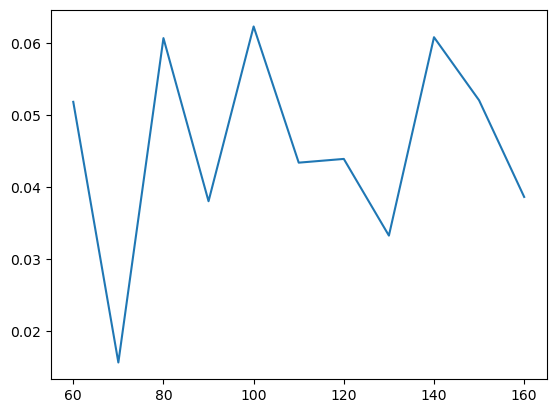

In [47]:
avgstart=[]
for i in distancetomeanAll2:
    plt.plot([x for x in range(60,170,10)],i)
    avgstart.append(i[0])

print(np.mean(avgstart))
plt.savefig("SVG/MultiGoalIncreasedmeanFailSafe2.svg")

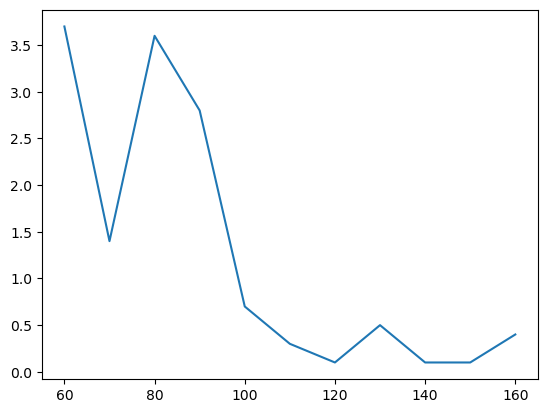

In [48]:
plt.plot([x for x in range(60,170,10)],repetioncounters)
plt.savefig("SVG/MultiGoalIncreasedmeanFailSafe3.svg")

In [12]:
distancetomeanAll3=[]
distancetoSTDAll3=[]
for goal in range(110,140,10):
    distancetomean=[]
    distancetostd=[]
    good=False
    while not good:
        _,_,_,agent=uniTraining(goal,episodeNumber=30000,type="inc",p=3.5)
        agent,testmean=failSafeTrain(agent,goal)
        if testmean  < 0.1 * goal:
            good=True
        else:
            print("repeat",testmean)
    for type in range(0,101):
        mean=[]
        std=[]
        for i in range(10):
            testresult=uniTest(agent,epsilon=type/100)
            mean.append(testresult[0])
            std.append(testresult[1])
        print(goal,np.mean(mean),np.mean(std))
        distancetomean.append(np.mean(mean))
        distancetostd.append(np.mean(std))
    distancetomeanAll3.append(distancetomean)
    distancetoSTDAll3.append(distancetostd)

110 116.20420000000001 3.1389983448157435
110 115.7415 4.953670627152983
110 115.16719999999998 7.3227332471638364
110 114.393 9.388991196210013
110 113.6736 11.43020247834577
110 112.96110000000002 12.96611664219779
110 112.269 14.47040686913338
110 111.4458 15.517237531844831
110 110.2954 17.85071489009085
110 109.3183 19.26730934620126
110 108.0923 21.1249658454416
110 107.1191 22.30678158112835
110 105.3135 24.582880872278004
110 104.51280000000001 25.698935828809727
110 102.5767 27.248626625583977
110 102.15360000000001 27.59443585154146
110 100.5745 29.23840131787968
110 98.49849999999999 30.768127319184792
110 96.9974 32.27740456928968
110 95.98620000000001 32.62859784734707
110 93.9906 33.713349644934326
110 92.62180000000001 34.83007157242495
110 91.3061 35.1916680556959
110 89.0663 36.79588458410323
110 87.3147 37.24572486122459
110 85.66479999999999 38.01226882714448
110 83.7703 38.931724092362096
110 82.66029999999999 39.34478268802127
110 81.53940000000001 39.6543902313712

122.6798


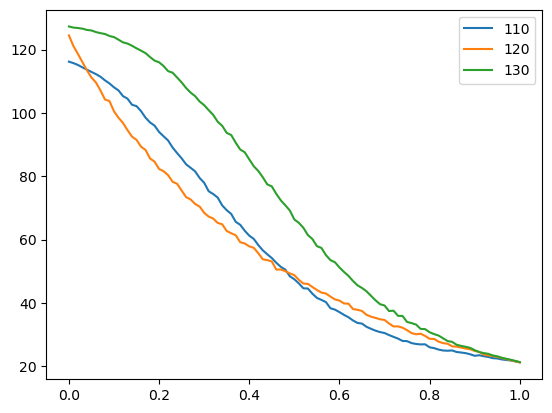

In [13]:
avgstart=[]
for i in distancetomeanAll3:
    plt.plot([x/100 for x in range(0,101)],i)
    avgstart.append(i[0])

print(np.mean(avgstart))
plt.legend([x for x in range(110,140,10)])
plt.savefig("SVG/MultiGoalIncreasedRand1.svg")

12.644672372100956


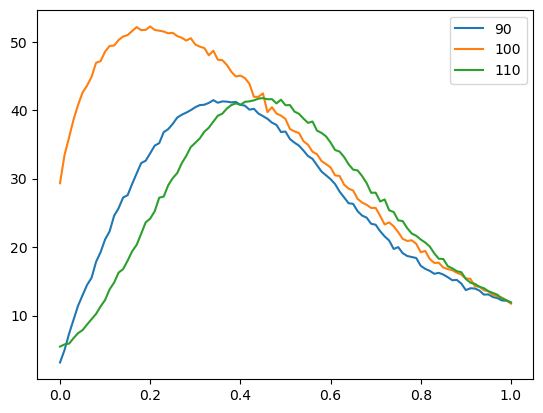

In [14]:
avgstart=[]
for i in distancetoSTDAll3:
    plt.plot([x/100 for x in range(0,101)],i)
    avgstart.append(i[0])

print(np.mean(avgstart))
plt.legend([x for x in range(90,150,10)])
plt.savefig("SVG/MultiGoalIncreasedRan2.svg")

y = 94.52x² + -200.76x + 126.23
y = 94.71x² + -189.59x + 118.93
y = 32.54x² + -159.68x + 140.39


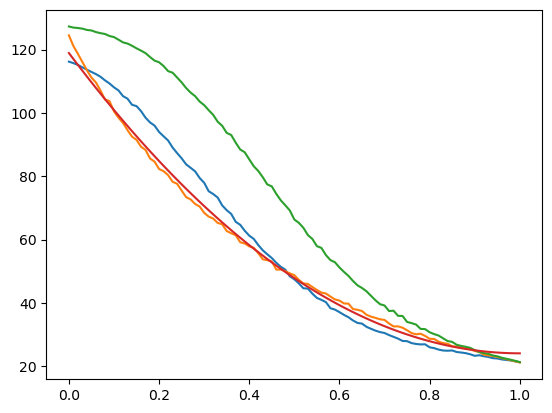

In [34]:
x_points = np.linspace(0,1,101)
coeffsall=[]
polyall=[]
for i in range(len(distancetomeanAll3)):
    coeffsall.append(np.polyfit(x_points, distancetomeanAll3[i], deg=2))
    polyall.append(np.poly1d(coeffsall[i]))
    
 
x_fit = np.linspace(min(x_points), max(x_points), 100)
y_fitall=[]
for i in polyall:
    y_fitall.append(i(x_fit))

equationall=[]
for i in coeffsall:
    equationall.append(f"y = {i[0]:.2f}x² + {i[1]:.2f}x + {i[2]:.2f}")
    print(f"y = {i[0]:.2f}x² + {i[1]:.2f}x + {i[2]:.2f}")



for i in distancetomeanAll3:
    plt.plot([x/100 for x in range(0,101)],i)
#plt.plot(x_fit, y_fitall[2], color='blue')
n=120
coefftest=[-0.3118 * n**2 + 71.733 * n - 4023.33,0.0937 * n**2 - 20.434 * n + 913.21, 0.1438 * n**2 - 33.804 * n + 2104.69]
#coefftest=[-3.099 * n -  435.41,2.054 * n + -426.7,  0.708 * n + 48.35]
polytest = np.poly1d(coefftest)  
y_fittest = polytest(x_fit)
plt.plot(x_fit,y_fittest)


In [28]:
# Use only n = 110 and n = 130
n_values_2 = np.array([110, 130])

# Corresponding coefficients for these n values
a_vals_2 = np.array([94.52, 32.54])
b_vals_2 = np.array([-200.76, -159.68])
c_vals_2 = np.array([126.23, 140.39])

# Fit a linear function for scalability (since we have only two points)
A_fit_2 = np.polyfit(n_values_2, a_vals_2, 1)
B_fit_2 = np.polyfit(n_values_2, b_vals_2, 1)
C_fit_2 = np.polyfit(n_values_2, c_vals_2, 1)

# Display the new equations for A(n), B(n), and C(n)
A_fit_2, B_fit_2, C_fit_2

(array([ -3.099, 435.41 ]),
 array([   2.054, -426.7  ]),
 array([ 0.708, 48.35 ]))

y = -116.33x² + 103.85x + 13.51
y = -56.00x² + 14.93x + 45.98
y = -140.34x² + 140.25x + 2.97


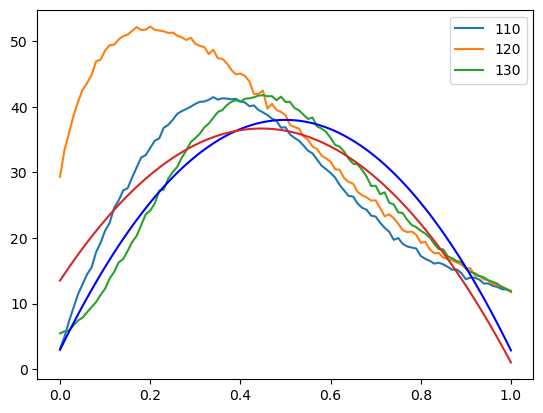

In [57]:
x_points = np.linspace(0,1,101)
coeffsall=[]
polyall=[]
for i in range(len(distancetoSTDAll3)):
    coeffsall.append(np.polyfit(x_points, distancetoSTDAll3[i], deg=2))
    polyall.append(np.poly1d(coeffsall[i]))
    
 
x_fit = np.linspace(min(x_points), max(x_points), 100)
y_fitall=[]
for i in polyall:
    y_fitall.append(i(x_fit))

equationall=[]
for i in coeffsall:
    equationall.append(f"y = {i[0]:.2f}x² + {i[1]:.2f}x + {i[2]:.2f}")
    print(f"y = {i[0]:.2f}x² + {i[1]:.2f}x + {i[2]:.2f}")



for i in distancetoSTDAll3:
    plt.plot([x/100 for x in range(0,101)],i)
#plt.plot(x_fit, y_fitall[0], color='blue')
#plt.plot(x_fit, y_fitall[1], color='blue')
plt.plot(x_fit, y_fitall[2], color='blue')
n=110
coefftest=[-0.72335*(n**2) + 172.4035* n -10328.18,   1.0712*(n**2)-255.268 * n + 15221.81, -0.3774*(n)**2+90.049*n - 5325.34]
#coefftest=[-104.22,  86.34, 20.82]
polytest = np.poly1d(coefftest)  
y_fittest = polytest(x_fit)
plt.legend([x for x in range(110,140,10)])
plt.plot(x_fit,y_fittest)

In [ ]:
v= 130
coefftest=[90 - (v-90)/5,-190, v+30]
polytest = np.poly1d(coefftest)  
y_fittest = polytest(x_fit)
plt.plot(x_fit, y_fittest, color='red', label=equation)
plt.plot(x_fit, y_fit3, color='blue', label=equation)
plt.plot([x/100 for x in range(0,101)],distancetomeanAll3[4])

In [ ]:
x_points = np.linspace(0,1,101)
x_fit = np.linspace(min(x_points), max(x_points), 100)
distancetoestall=[]
for goal in range(90,150,10):
    coefftest=[-0.45*goal+128.77,-0.22*goal-168.10, 0.53*goal+72.33]
    polytest = np.poly1d(coefftest)  
    y_fittest = polytest(x_fit)
   
    distancetoest=[]
    _,_,_,agent=uniTraining(goal,episodeNumber=30000,type="inc",p=3.5)
    for type in range(0,100):
        mean=[]
        std=[]
        for i in range(10):
            testresult=uniTest(agent,epsilon=type/100)
            mean.append(testresult[0])
            std.append(testresult[1])
        print(goal,np.mean(mean),np.mean(std),abs(np.mean(mean) - y_fittest[type]) )
        distancetoest.append(abs(np.mean(mean) - y_fittest[type]) )
        
    distancetoestall.append(distancetoest)
    

In [ ]:
for i in distancetoestall:
    plt.plot([x/100 for x in range(0,100)],i)
plt.legend([x for x in range(90,150,10)])
plt.savefig("SVG/Estimation1.svg")

In [ ]:
distancetomeanAll3=[]
distancetoSTDAll3=[]
for goal in range(120,200,10):
    distancetomean=[]
    distancetostd=[]
    _,_,_,agent=uniTraining(goal,episodeNumber=30000,type="inc",p=3.5)
    for type in range(0,101):
        mean=[]
        std=[]
        for i in range(10):
            testresult=uniTest(agent,epsilon=type/100)
            mean.append(testresult[0])
            std.append(testresult[1]) 
        print(goal,np.mean(mean),np.mean(std))
        if np.mean(mean) < 130 - 13 and len(distancetomean)>0 and distancetomean[-1]<130-13:
            break
        distancetomean.append(np.mean(mean))
        distancetostd.append(np.mean(std))
    distancetomeanAll3.append(distancetomean)
    distancetoSTDAll3.append(distancetostd)

In [ ]:
avgstart=[]
for i in distancetomeanAll3[1:-4]:
    plt.plot([x/100 for x in range(0,101)][:len(i)],i)
    avgstart.append(i[0])

print(np.mean(avgstart))
plt.legend([x for x in range(130,200,10)])
plt.savefig("SVG/MultiGoalIncreasedRan3.svg")

In [ ]:
avgstart=[]
for i in distancetomeanAll3[1:-1]:
    plt.plot([x/100 for x in range(0,101)][:len(i)],i)
    avgstart.append(i[0])

print(np.mean(avgstart))
plt.legend([x for x in range(130,200,10)])
plt.savefig("SVG/MultiGoalIncreasedRan4.svg")

In [ ]:
avgstart=[]
for i in distancetoSTDAll3[1:-4]:
    plt.plot([x/100 for x in range(0,101)][:len(i)],i)
    avgstart.append(i[0])

print(np.mean(avgstart))
plt.legend([x for x in range(130,200,10)])